In [ ]:
import pandas as pd
from pathlib import Path 
from matplotlib import pyplot as plt
import seaborn as sns   
DATA_PATH = Path("../data")
csv_files = list(DATA_PATH.glob("*.csv"))
df = pd.read_csv("../data/ai4i2020.csv")
print("Dataset Shape:", df.shape)
print("\n Column Names:", df.columns.tolist())
print("\n Dataset Info:",df.info())
print("First five rows of the dataset:\n", df.head())

In [7]:
print("Missing Values in the dataset:", df.isnull().sum())
print("\nDuplicate Rows in the dataset:", df.duplicated().sum())
print("\nMachine Failure: ", df["Machine failure"].value_counts())
print("\nFailure Percentage: ", (df["Machine failure"].value_counts(normalize=True) * 100).round(2))


Missing Values in the dataset: UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Duplicate Rows in the dataset: 0

Machine Failure:  Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure Percentage:  Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)
print("Training Set Shape:", X_train.shape, y_train.shape)
print("Test Set Shape:", X_test.shape, y_test.shape)

Target Distribution: 
Machine failure
No Failure    9661
Failure        339
Name: count, dtype: int64

Failure Rate: 
3.39%


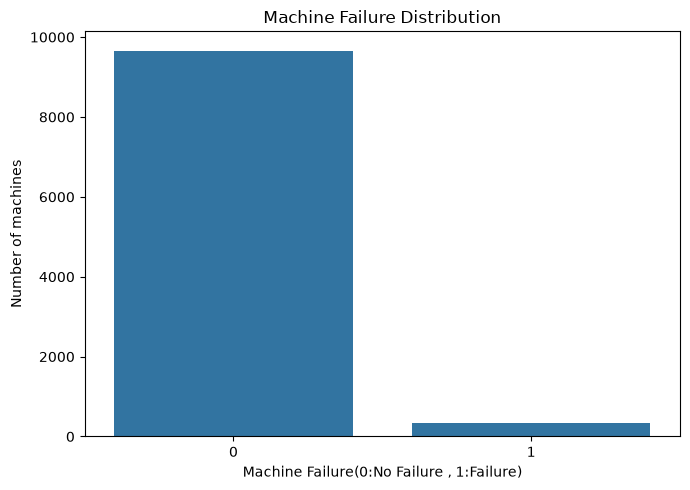

In [3]:
failure_counts = df["Machine failure"].value_counts().sort_index()
print("Target Distribution: ")
print(failure_counts.rename(index = {0: "No Failure", 1: "Failure"}))
print("\nFailure Rate: ")
print(f"{df['Machine failure'].mean() * 100:.2f}%")
#Visualize
plt.figure(figsize = (7,5))
sns.countplot(x = "Machine failure", data = df)
plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure(0:No Failure , 1:Failure)")
plt.ylabel("Number of machines")
plt.tight_layout()
plt.show()


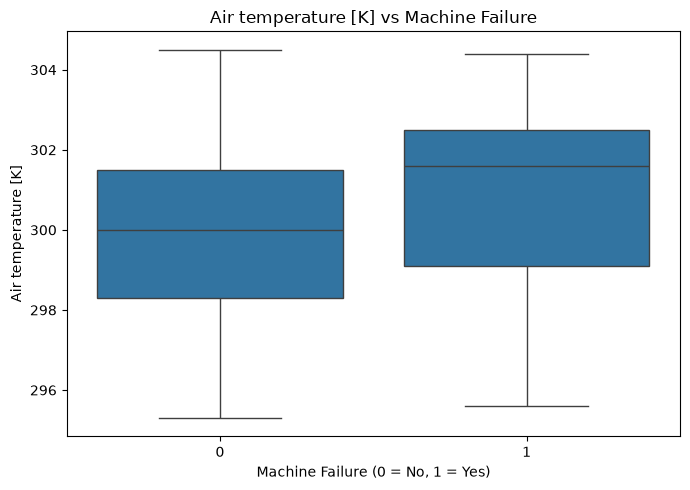

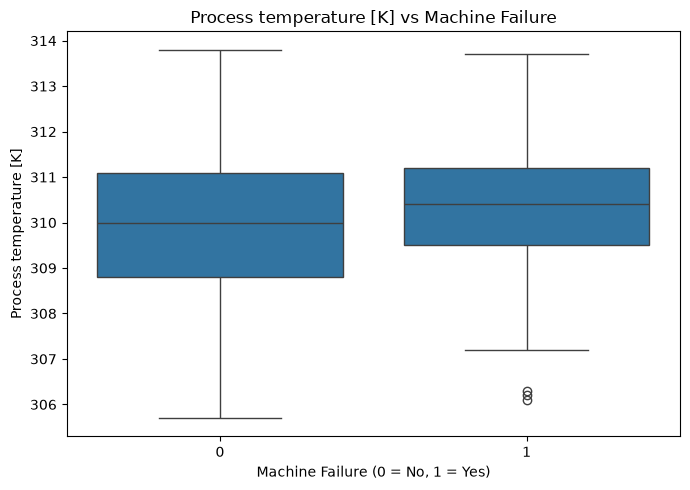

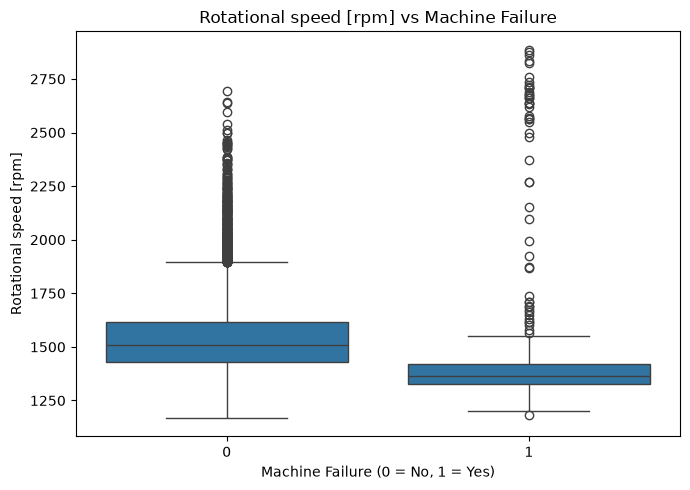

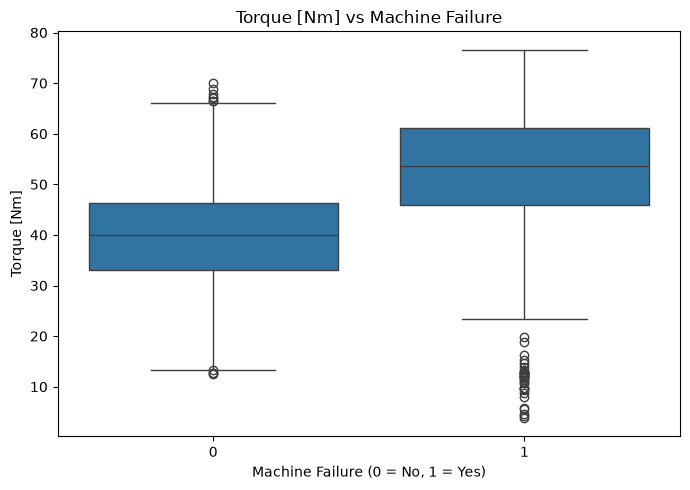

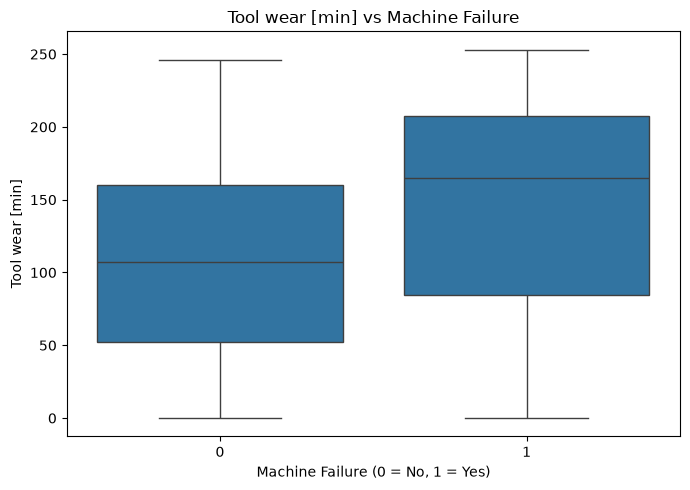

In [8]:
sensor_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]
# Compare sensor readings for failed and non-failed machines
for feature in sensor_features:
    plt.figure(figsize=(7,5))
    sns.boxplot(
        x="Machine failure",
        y=feature,
        data=df
    )

    plt.title(f"{feature} vs Machine Failure")
    plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
    plt.tight_layout()
    plt.show()